# 2 · A first learned upscaler

A plain convolutional network (CNN) that makes the **whole picture itself**: no bicubic underneath it. It is trained
with the recipe every model notebook shares (`training.fit`) on notebook 0's training split, and scored on its
validation split exactly as notebook 1 scored the filters (`training.val_scores`), so the numbers sit in one table with
every other notebook's (notebook 29).

Two shapes:

- **16-24-24-32**, the small default: about as much work as the client can afford per pixel;
- **64-32**, twice the work: the smallest plain shape that beat bicubic on the earlier sets.

The residual version, bicubic plus a learned correction, is notebook 3.

Needs: `00_data_preprocess.ipynb`, and `01_upscale_dummy.ipynb` for bicubic's recorded scores, the bar.

In [1]:
"""Settings."""

import os

import numpy as np
import torch
import torch.nn as nn

os.environ["DATASETS_DIR"] = "/mnt/d/datasets"   # where the datasets are: set before helpers is imported

from helpers import models, patches, speed, training, webexport
from helpers.training import DATA_DIR, DEVICE

NOTEBOOK = 2
# name: (widths of the hidden convolutions, their kernels, the output convolution's kernel); each reaches 4 LR pixels
SHAPES = {
    "plain CNN 16-24-24-32": ((16, 24, 24, 32), (3, 3, 3, 1), 3),
    "plain CNN 64-32": ((64, 32), (5, 3), 3),
}

manifest = training.load_manifest()
SCALE = manifest["scale"]
bicubic = training.recorded()[1, "bicubic"]   # notebook 1's scores of the bar

## 1. The model

Shaped like ESPCN (Shi et al., 2016):

    LR picture -> conv -> ReLU -> ... -> output conv -> PixelShuffle -> HR picture

- Every convolution works at **low** resolution: 4× cheaper than upscaling first.
- The output convolution makes `3 × scale²` channels, the colours of the `scale × scale` HR pixels each LR pixel turns
  into, and `PixelShuffle` moves them into place.
- No bicubic shortcut: the network rebuilds the picture, colour included, from random weights.

**Halo.** A k×k convolution sees k // 2 pixels further out, and the layers add up. The total must fit the halo of 4
that the patches and the client's tiles have, or pixels at a tile's edge come out wrong.

In [2]:
class PlainCNN(nn.Module):
    """LR picture in, HR picture out: convolutions at low resolution, then one PixelShuffle."""

    def __init__(self, scale, widths, kernels, tail_kernel):
        super().__init__()
        layers, channels = [], 3
        for width, kernel in zip(widths, kernels):
            layers += [nn.Conv2d(channels, width, kernel, padding=kernel // 2), nn.ReLU(inplace=True)]
            channels = width
        # the output: 3 colours for each of the scale x scale HR pixels of every LR pixel
        layers += [nn.Conv2d(channels, 3 * scale * scale, tail_kernel, padding=tail_kernel // 2),
                   nn.PixelShuffle(scale)]
        self.net = nn.Sequential(*layers)
        self.halo = sum(kernel // 2 for kernel in kernels) + tail_kernel // 2

    def forward(self, x):
        return self.net(x)


built = {}
for name, (widths, kernels, tail_kernel) in SHAPES.items():
    torch.manual_seed(0)
    model = PlainCNN(SCALE, widths, kernels, tail_kernel).to(DEVICE)
    assert model.halo <= manifest["halo"], f"{name} reaches further than the patches' halo"
    built[name] = model
    print(f"{name}: {models.count_parameters(model):,} parameters, halo {model.halo}, "
          f"{speed.macs_per_lr_pixel(model):,.0f} multiply-adds per LR pixel")

plain CNN 16-24-24-32: 13,404 parameters, halo 4, 13,296 multiply-adds per LR pixel
plain CNN 64-32: 26,796 parameters, halo 4, 26,688 multiply-adds per LR pixel


## 2. Train

`training.fit`, the same for every model notebook: Adam at 1e-3, batches of 32, the loss `metrics.ssim_l1_loss`
(0.84 × (1 − SSIM on luma) + 0.16 × L1 on RGB), an epoch of 34,368 training patches drawn afresh with random flips and
rotations. After every epoch the **select** split (held-out training sources) is scored, and the epoch with the best
SSIM-Y is kept; the learning rate halves after 6 epochs without improvement, and training stops once even 1e-5 does not
help. The validation split is not touched until section 3.

The training is saved to `checkpoints/` after every epoch, so running the cell again carries on, or loads the finished
result.

--- plain CNN 16-24-24-32
train  140795 patches
select   6982 patches, to choose the best epoch
Loaded the training saved in /home/henrik/projects/desktop-streamer-ai/src/upscale/checkpoints/upscale_nn_16-24-24-32.pt: 134 epochs done in 111.1 min, best epoch 128 (val_ssim_y: 0.8870), learning rate now 1.0e-05.
It had finished (converged - no improvement in 6 epochs, even at the smallest learning rate), so nothing is trained again - delete the file to train from the start.
Restoring model weights from the end of the best epoch: 128 (val_ssim_y: 0.8870, +0.7873 over the untrained model). Training took 134 epochs, 111.1 min.
--- plain CNN 64-32
train  140795 patches
select   6982 patches, to choose the best epoch
Loaded the training saved in /home/henrik/projects/desktop-streamer-ai/src/upscale/checkpoints/upscale_nn_64-32.pt: 126 epochs done in 113.9 min, best epoch 120 (val_ssim_y: 0.8875), learning rate now 1.0e-05.
It had finished (converged - no improvement in 6 epochs, even at the s

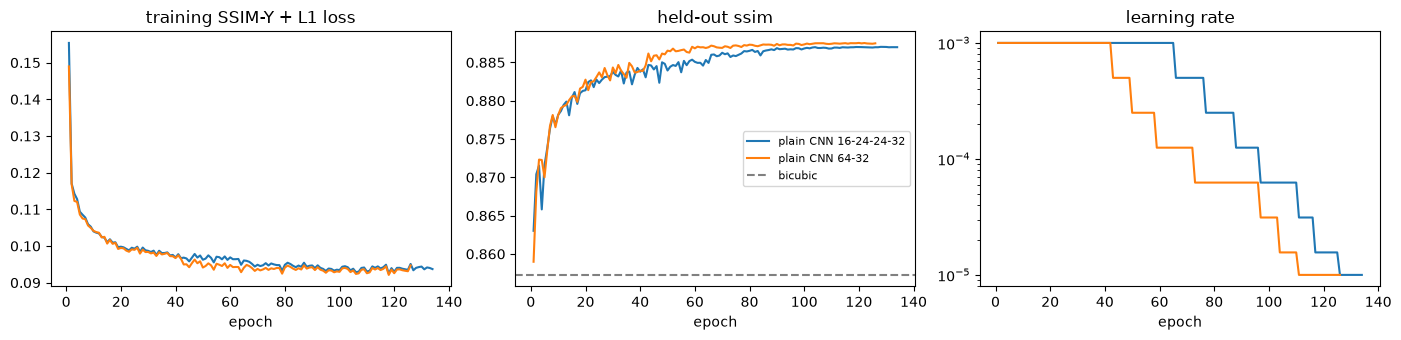

In [3]:
histories = {}
for name, model in built.items():
    print(f"--- {name}")
    checkpoint = training.CHECKPOINT_DIR / f"upscale_nn_{name.removeprefix('plain CNN ')}.pt"
    histories[name], best = training.fit(model, checkpoint, manifest)

training.plot_history(histories, training.select_bicubic(manifest), key="ssim", loss_name="SSIM-Y + L1 loss")

## 3. Scores

Every validation patch's SSIM-Y and luma PSNR; the gain over bicubic with its 95% range from a bootstrap over the
sources, then by kind and encoder line, and by slice QP.

In [4]:
results = {"bicubic": bicubic}
for name, model in built.items():
    model.eval()
    results[name] = training.val_scores(lambda lr, condition: model(lr), manifest)
    training.record(NOTEBOOK, name, results[name])

training.show(training.compare(results, manifest, base=bicubic))
print()
training.show(training.gain_by_qp(results, manifest, base=bicubic))

                model SSIM-Y over bicubic          95% range luma dB dB over chroma dB over   video  screen   photo    x264   nvenc
      plain CNN 64-32 0.8872      +0.0351 +0.0328 to +0.0375   29.81   +1.23          -3.05 +0.0191 +0.0540 +0.0185 +0.0366 +0.0336
plain CNN 16-24-24-32 0.8867      +0.0346 +0.0323 to +0.0369   29.72   +1.14          -3.66 +0.0186 +0.0535 +0.0176 +0.0360 +0.0331
              bicubic 0.8521      +0.0000 +0.0000 to +0.0000   28.58   +0.00          +0.00 +0.0000 +0.0000 +0.0000 +0.0000 +0.0000

                model    0-18   18-26   26-30   30-34   34-38   38-42   42-46   46-52
              patches    3610    3928    3730    3585    3539    2846    2005    1043
              bicubic +0.0000 +0.0000 +0.0000 +0.0000 +0.0000 +0.0000 +0.0000 +0.0000
plain CNN 16-24-24-32 +0.0298 +0.0338 +0.0368 +0.0377 +0.0372 +0.0374 +0.0305 +0.0268
      plain CNN 64-32 +0.0305 +0.0344 +0.0372 +0.0382 +0.0378 +0.0380 +0.0309 +0.0268


### What it looks like

Four validation screens at a slice QP under 26, where the stream leaves the detail for an upscaler to keep: text and
window edges are what a desktop is made of.

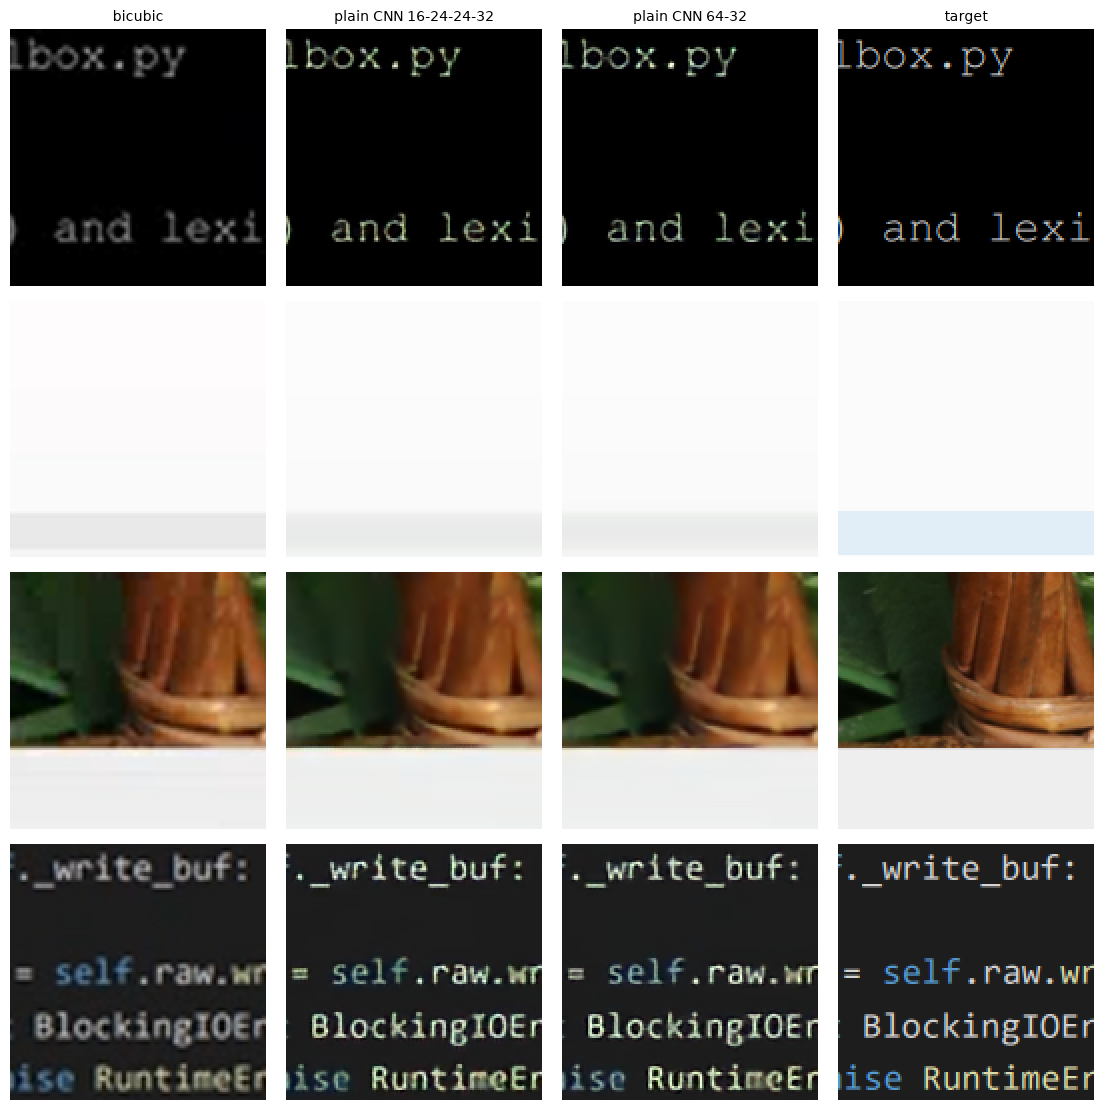

In [5]:
labels = {name: np.load(DATA_DIR / manifest["splits"]["val"][name]) for name in ("kind", "qp")}
screens = np.flatnonzero((labels["kind"] == manifest["kinds"].index("screen")) & (labels["qp"] < 26))
picked = screens[np.linspace(0, len(screens) - 1, 4).astype(int)]

val = patches.PatchPairs(DATA_DIR, "val", manifest, augment=False)
lr = torch.stack([val[i][0] for i in picked]).to(DEVICE)
hr = torch.stack([val[i][1] for i in picked]).to(DEVICE)
trim = training.trimmer(manifest)
with torch.no_grad():
    training.show_patches({"bicubic": trim(models.bicubic(lr, SCALE)),
                           **{name: trim(model(lr)) for name, model in built.items()}, "target": hr})

## 4. Export for the browser

Each shape at the client's tile (320×180 LR pixels a step plus the halo of 4) and as a whole 1080p frame, checked
against torch and timed on this CPU. The graph is only `Conv`, `Relu` and `DepthToSpace` (ONNX's `PixelShuffle`), all
in the browser's fast operator set, so the lines below should flag nothing.

In [6]:
for name, model in built.items():
    webexport.publish(model, f"upscale_nn_{name.removeprefix('plain CNN ')}", model.halo, label=f"nn - {name}",
                      scale=SCALE)
print("compare in a browser: uv run src/upscale/benchmark/main.py")

upscale_nn_16-24-24-32_tile320x180.onnx                54.2 KB    4.79 ms   Convx5, DepthToSpacex1, Relux4
upscale_nn_16-24-24-32_tile320x180_frame.onnx          54.7 KB   49.11 ms   Convx5, DepthToSpacex1, Relux4
upscale_nn_64-32_tile320x180.onnx                     105.8 KB   10.56 ms   Convx3, DepthToSpacex1, Relux2
upscale_nn_64-32_tile320x180_frame.onnx               106.1 KB   82.47 ms   Convx3, DepthToSpacex1, Relux2
compare in a browser: uv run src/upscale/benchmark/main.py


## 5. What it says

- **Both shapes learn, and land together.** The 64-32 scores 0.8872 SSIM-Y, +0.0351 over bicubic (95% range +0.0328
  to +0.0375), and +1.23 dB of luma; the 16-24-24-32 0.8867, +0.0346. The 0.0005 between them is far inside either
  range, and the 64-32 pays twice the parameters (26,796 against 13,404) and twice the multiply-adds for it.
- **Screens gain most**: +0.054 SSIM-Y, against +0.018 to +0.019 on video and photos. By slice QP the gain is largest in the
  middle (+0.037 to +0.038 from 26 to 42) and smallest at both ends (+0.030 below 18, +0.027 from 46 to 52).
- **They cost colour.** These models make all three channels themselves, and their chroma is 3.1 to 3.7 dB below
  bicubic's. About half of that is on the 2,816 gray patches, where bicubic's colour is exact and the model adds a faint
  tint; pooled over the whole split it is 0.5 dB.
- **The timings rank, nothing more.** They were taken on this CPU while trainings ran on the same machine; notebook 5
  and the browser benchmark measure speed.